In [6]:
#3.1. Import thư viện
import pandas as pd
import numpy as np

# Chia và xử lý dữ liệu
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Hai thuật toán Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Đánh giá mô hình
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Lưu mô hình
import joblib

print("Đã import thư viện thành công!")


Đã import thư viện thành công!


In [7]:
#3.2. Đọc dữ liệu

data_path = "../data/processed/fraud_modeling_dataset.csv"

# Đọc dữ liệu
df = pd.read_csv(data_path)

# Kiểm tra kích thước
print("Số giao dịch:", df.shape[0])
print("Số cột:", df.shape[1])

# Hiển thị 5 giao dịch đầu tiên
display(df.head())


Số giao dịch: 30000
Số cột: 23


,transaction_id,transaction_at,amount,channel,type_code,hour,day_of_week,is_night_transaction,account_age_days,txn_count_1h,...,avg_amount_30d,max_amount_30d,amount_to_avg_ratio,failed_login_count_24h,successful_login_count_24h,failed_login_count_1h,time_since_last_transaction,login_failure_ratio_24h,is_fraud,labeled_at
0,1,2026-01-01 00:00:15,614000.0,InternetBanking,TRANSFER,0,5,1,731,0,...,NaN,NaN,NaN,0,1,0,NaN,0.0,0,2026-01-08 00:00:15
1,2,2026-01-01 00:20:14,20877000.0,ATM,TRANSFER,0,5,1,731,0,...,NaN,NaN,NaN,0,0,0,NaN,0.0,0,2026-01-07 00:20:14
2,3,2026-01-01 00:28:19,63286000.0,InternetBanking,TRANSFER,0,5,1,731,0,...,NaN,NaN,NaN,3,1,3,NaN,0.6,1,2026-01-11 00:28:19
3,4,2026-01-01 01:04:46,3586000.0,MobileBanking,TRANSFER,1,5,1,731,0,...,NaN,NaN,NaN,0,1,0,NaN,0.0,0,2026-01-09 01:04:46
4,5,2026-01-01 01:13:14,1995000.0,MobileBanking,TRANSFER,1,5,1,731,0,...,NaN,NaN,NaN,0,1,0,NaN,0.0,1,2026-01-10 01:13:14


In [8]:

# 3.3. Chia dữ liệu theo thời gian

# Chuyển cột thời gian sang datetime
df["transaction_at"] = pd.to_datetime(df["transaction_at"])
df["labeled_at"] = pd.to_datetime(df["labeled_at"])

# Sắp xếp giao dịch từ cũ đến mới
df = df.sort_values(
    ["transaction_at", "transaction_id"]
).reset_index(drop=True)

# Xác định vị trí chia dữ liệu
train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

# Chia thành 3 tập
train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

# Thời điểm bắt đầu Validation và Test
val_start = val_df["transaction_at"].min()
test_start = test_df["transaction_at"].min()

# Chỉ sử dụng nhãn đã được xác nhận đúng thời điểm
train_df = train_df[train_df["labeled_at"] <= val_start].copy()
val_df = val_df[val_df["labeled_at"] <= test_start].copy()

# Kiểm tra dữ liệu sau khi chia
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(data)} giao dịch")
    print(f"  Gian lận: {data['is_fraud'].sum()}")
    print(f"  Tỷ lệ gian lận: {data['is_fraud'].mean():.2%}")

# Kiểm tra tránh rò rỉ dữ liệu
assert train_df["transaction_at"].max() < val_df["transaction_at"].min()
assert val_df["transaction_at"].max() < test_df["transaction_at"].min()

assert (train_df["labeled_at"] <= val_start).all()
assert (val_df["labeled_at"] <= test_start).all()

print("\nChia dữ liệu thành công!")


Train: 20119 giao dịch
  Gian lận: 1959
  Tỷ lệ gian lận: 9.74%
Validation: 3610 giao dịch
  Gian lận: 299
  Tỷ lệ gian lận: 8.28%
Test: 4500 giao dịch
  Gian lận: 422
  Tỷ lệ gian lận: 9.38%

Chia dữ liệu thành công!


In [9]:
# 3.4. Chuẩn bị dữ liệu cho mô hình

#3.4.1
# Các cột không dùng làm feature
drop_cols = [
    "transaction_id",
    "transaction_at",
    "labeled_at",
    "is_fraud"
]

# Lấy danh sách feature
features = df.drop(columns=drop_cols).columns.tolist()

# Tách dữ liệu đầu vào (X) và nhãn (y)
X_train = train_df[features]
y_train = train_df["is_fraud"]

X_val = val_df[features]
y_val = val_df["is_fraud"]

X_test = test_df[features]
y_test = test_df["is_fraud"]

print("Số feature:", len(features))
print("Kích thước Train:", X_train.shape)
print("Kích thước Validation:", X_val.shape)
print("Kích thước Test:", X_test.shape)

assert len(features) == 19


Số feature: 19
Kích thước Train: (20119, 19)
Kích thước Validation: (3610, 19)
Kích thước Test: (4500, 19)


In [10]:
#3.4.2. Phân loại feature


# Phân loại feature số
num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Phân loại feature chữ
cat_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Kiểm tra kết quả
print("Số feature số:", len(num_cols))
print("Số feature chữ:", len(cat_cols))

print("Feature chữ:", cat_cols)

assert len(num_cols) == 17
assert len(cat_cols) == 2


Số feature số: 17
Số feature chữ: 2
Feature chữ: ['channel', 'type_code']


In [11]:
#3.4.3. Xây dựng Preprocessing Pipeline
# Xử lý dữ liệu số
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Xử lý dữ liệu chữ
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Kết hợp thành bộ xử lý chung
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Tạo Preprocessing Pipeline thành công!")


Tạo Preprocessing Pipeline thành công!


In [12]:
# 3.5 - Huấn luyện các mô hình

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Khởi tạo các mô hình Baseline
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Huấn luyện từng mô hình
trained_models = {}

for name, estimator in models.items():

    # Tạo Pipeline riêng cho từng mô hình
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    # Huấn luyện trên tập Train
    model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"Đã huấn luyện: {name}")

# Giữ tên biến tương thích với các cell phía sau
lr_model = trained_models["Logistic Regression"]
rf_model = trained_models["Random Forest"]
xgb_model = trained_models["XGBoost"]


Đã huấn luyện: Logistic Regression
Đã huấn luyện: Random Forest
Đã huấn luyện: XGBoost


In [13]:
# 3.6 - Đánh giá các mô hình trên Validation

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Danh sách các mô hình đã huấn luyện ở mục 3.5
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

# Ngưỡng dự đoán mặc định
threshold = 0.5
results = []

for name, model in models.items():

    # Dự đoán xác suất gian lận
    probabilities = model.predict_proba(X_val)[:, 1]

    # Chuyển xác suất thành nhãn
    predictions = (probabilities >= threshold).astype(int)

    # Tính các chỉ số đánh giá
    results.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        )
    })

# Tạo bảng so sánh
baseline_comparison = pd.DataFrame(results)

# Sắp xếp theo F1-score giảm dần
baseline_comparison = baseline_comparison.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

display(baseline_comparison.round(4))


,Model,Threshold,Precision,Recall,F1-score,PR-AUC
0,Random Forest,0.5,0.9256,0.6656,0.7743,0.8443
1,XGBoost,0.5,0.9543,0.6288,0.7581,0.8277
2,Logistic Regression,0.5,0.4066,0.7793,0.5344,0.7803


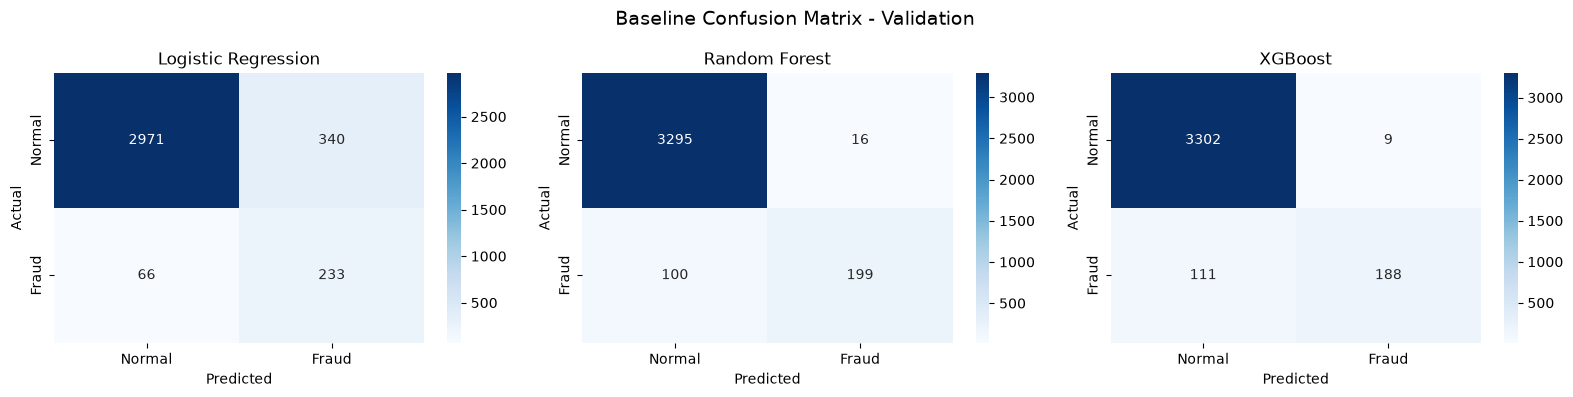

In [14]:
# 3.6.2 - Confusion Matrix của ba mô hình

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Các mô hình Baseline đã huấn luyện
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

# Vẽ Confusion Matrix cho ba mô hình
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(axes, models.items()):

    # Dự đoán với threshold = 0.5
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    # Tính Confusion Matrix
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])

    # Hiển thị biểu đồ
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Fraud"],
        yticklabels=["Normal", "Fraud"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Baseline Confusion Matrix - Validation", fontsize=14)
plt.tight_layout()
plt.show()


In [15]:
# 3.7.1 - Tối ưu Hyperparameter Logistic Regression

from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

# Các bộ tham số cần thử
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

best_lr_score = -1
best_lr_params = None
best_lr_model = None

for params in ParameterGrid(lr_param_grid):

    # Tạo mô hình với bộ tham số hiện tại
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            **params,
            max_iter=1000,
            random_state=42
        ))
    ])

    # Huấn luyện trên Train
    model.fit(X_train, y_train)

    # Đánh giá trên Validation
    probabilities = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probabilities)

    print(params, "PR-AUC:", round(score, 4))

    # Lưu mô hình tốt nhất
    if score > best_lr_score:
        best_lr_score = score
        best_lr_params = params
        best_lr_model = model

print("\nTham số Logistic Regression tốt nhất:", best_lr_params)
print("PR-AUC tốt nhất:", round(best_lr_score, 4))


{'C': 0.01, 'class_weight': None} PR-AUC: 0.7706
{'C': 0.01, 'class_weight': 'balanced'} PR-AUC: 0.7765
{'C': 0.1, 'class_weight': None} PR-AUC: 0.7783
{'C': 0.1, 'class_weight': 'balanced'} PR-AUC: 0.7807
{'C': 1, 'class_weight': None} PR-AUC: 0.7776
{'C': 1, 'class_weight': 'balanced'} PR-AUC: 0.7803
{'C': 10, 'class_weight': None} PR-AUC: 0.777
{'C': 10, 'class_weight': 'balanced'} PR-AUC: 0.78

Tham số Logistic Regression tốt nhất: {'C': 0.1, 'class_weight': 'balanced'}
PR-AUC tốt nhất: 0.7807


In [16]:
# 3.7.2 - Tối ưu Hyperparameter Random Forest

from sklearn.ensemble import RandomForestClassifier

# Các bộ tham số cần thử
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

best_rf_score = -1
best_rf_params = None
best_model = None

for params in ParameterGrid(rf_param_grid):

    # Tạo mô hình với bộ tham số hiện tại
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            **params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Huấn luyện trên Train
    model.fit(X_train, y_train)

    # Đánh giá trên Validation
    probabilities = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probabilities)

    print(params, "PR-AUC:", round(score, 4))

    # Lưu mô hình tốt nhất
    if score > best_rf_score:
        best_rf_score = score
        best_rf_params = params
        best_model = model

print("\nTham số Random Forest tốt nhất:", best_rf_params)
print("PR-AUC tốt nhất:", round(best_rf_score, 4))


{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100} PR-AUC: 0.8423
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200} PR-AUC: 0.8469
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100} PR-AUC: 0.8416
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200} PR-AUC: 0.8488
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100} PR-AUC: 0.8411
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200} PR-AUC: 0.8477
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100} PR-AUC: 0.8372
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200} PR-AUC: 0.8476
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100} PR-AUC: 0.8514
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200} PR-AU

In [17]:
# 3.7.3 - Tối ưu Hyperparameter XGBoost

from xgboost import XGBClassifier

# Các bộ tham số cần thử
xgb_param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.05]
}

best_xgb_score = -1
best_xgb_params = None
best_xgb_model = None

for params in ParameterGrid(xgb_param_grid):

    # Tạo mô hình với bộ tham số hiện tại
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBClassifier(
            **params,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Huấn luyện trên Train
    model.fit(X_train, y_train)

    # Đánh giá trên Validation
    probabilities = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probabilities)

    print(params, "PR-AUC:", round(score, 4))

    # Lưu mô hình tốt nhất
    if score > best_xgb_score:
        best_xgb_score = score
        best_xgb_params = params
        best_xgb_model = model

print("\nTham số XGBoost tốt nhất:", best_xgb_params)
print("PR-AUC tốt nhất:", round(best_xgb_score, 4))


{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200} PR-AUC: 0.8419
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300} PR-AUC: 0.8514
{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200} PR-AUC: 0.8634
{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 300} PR-AUC: 0.8598
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200} PR-AUC: 0.8529
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300} PR-AUC: 0.8541
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200} PR-AUC: 0.8596
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300} PR-AUC: 0.8556

Tham số XGBoost tốt nhất: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200}
PR-AUC tốt nhất: 0.8634


In [18]:
# 3.8.1 - Tối ưu Threshold Logistic Regression

# Dự đoán xác suất trên Validation
lr_probs = best_lr_model.predict_proba(X_val)[:, 1]

# Thử các threshold với bước 0.001
thresholds = np.round(np.arange(0.001, 1.0, 0.001), 3)
results = []

for threshold in thresholds:
    predictions = (lr_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0)
    })

# Tạo bảng kết quả
lr_threshold_df = pd.DataFrame(results)

# Chọn threshold có F1-score cao nhất
best_lr_row = lr_threshold_df.loc[
    lr_threshold_df["F1-score"].idxmax()
]

best_lr_threshold = float(best_lr_row["Threshold"])

# Hiển thị kết quả tối ưu
print("Threshold:", best_lr_threshold)
print("Precision:", round(best_lr_row["Precision"], 4))
print("Recall:", round(best_lr_row["Recall"], 4))
print("F1-score:", round(best_lr_row["F1-score"], 4))

# Hiển thị bảng theo bước 0.05 và thêm ngưỡng tối ưu
display_thresholds = np.append(
    np.round(np.arange(0.10, 0.91, 0.05), 2),
    best_lr_threshold
)

display(
    lr_threshold_df[
        lr_threshold_df["Threshold"].isin(display_thresholds)
    ].sort_values("Threshold").round(4)
)


Threshold: 0.752
Precision: 0.8474
Recall: 0.7057
F1-score: 0.7701


,Threshold,Precision,Recall,F1-score
99,0.100,0.0868,1.0000,0.1598
149,0.150,0.1929,0.9699,0.3219
199,0.200,0.2465,0.8796,0.3851
249,0.250,0.2703,0.8562,0.4109
299,0.300,0.2855,0.8261,0.4244
349,0.350,0.3004,0.8127,0.4386
399,0.400,0.3220,0.7893,0.4574
449,0.450,0.3625,0.7893,0.4968
499,0.500,0.4066,0.7793,0.5344
549,0.550,0.4379,0.7659,0.5572


In [19]:
# 3.8.2 - Tối ưu Threshold Random Forest

# Dự đoán xác suất trên Validation
rf_probs = best_model.predict_proba(X_val)[:, 1]

# Thử các threshold với bước 0.001
thresholds = np.round(np.arange(0.001, 1.0, 0.001), 3)
results = []

for threshold in thresholds:
    predictions = (rf_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0)
    })

# Tạo bảng kết quả
rf_threshold_df = pd.DataFrame(results)

# Chọn threshold có F1-score cao nhất
best_rf_row = rf_threshold_df.loc[
    rf_threshold_df["F1-score"].idxmax()
]

best_rf_threshold = float(best_rf_row["Threshold"])

# Hiển thị kết quả tối ưu
print("Threshold:", best_rf_threshold)
print("Precision:", round(best_rf_row["Precision"], 4))
print("Recall:", round(best_rf_row["Recall"], 4))
print("F1-score:", round(best_rf_row["F1-score"], 4))

# Hiển thị bảng theo bước 0.05 và thêm ngưỡng tối ưu
display_thresholds = np.append(
    np.round(np.arange(0.10, 0.91, 0.05), 2),
    best_rf_threshold
)

display(
    rf_threshold_df[
        rf_threshold_df["Threshold"].isin(display_thresholds)
    ].sort_values("Threshold").round(4)
)


Threshold: 0.288
Precision: 0.8735
Recall: 0.7391
F1-score: 0.8007


,Threshold,Precision,Recall,F1-score
99,0.100,0.4015,0.8997,0.5552
149,0.150,0.5636,0.8294,0.6712
199,0.200,0.6946,0.7759,0.7330
249,0.250,0.7986,0.7559,0.7766
287,0.288,0.8735,0.7391,0.8007
299,0.300,0.8755,0.7291,0.7956
349,0.350,0.8903,0.7057,0.7873
399,0.400,0.9111,0.6856,0.7824
449,0.450,0.9309,0.6756,0.7829
499,0.500,0.9387,0.6656,0.7789


In [20]:
# 3.8.3 - Tối ưu Threshold XGBoost

# Dự đoán xác suất trên Validation
xgb_probs = best_xgb_model.predict_proba(X_val)[:, 1]

# Thử các threshold với bước 0.001
thresholds = np.round(np.arange(0.001, 1.0, 0.001), 3)
results = []

for threshold in thresholds:
    predictions = (xgb_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0)
    })

# Tạo bảng kết quả
xgb_threshold_df = pd.DataFrame(results)

# Chọn threshold có F1-score cao nhất
best_xgb_row = xgb_threshold_df.loc[
    xgb_threshold_df["F1-score"].idxmax()
]

best_xgb_threshold = float(best_xgb_row["Threshold"])

# Hiển thị kết quả tối ưu
print("Threshold:", best_xgb_threshold)
print("Precision:", round(best_xgb_row["Precision"], 4))
print("Recall:", round(best_xgb_row["Recall"], 4))
print("F1-score:", round(best_xgb_row["F1-score"], 4))

# Hiển thị bảng theo bước 0.05 và thêm ngưỡng tối ưu
display_thresholds = np.append(
    np.round(np.arange(0.10, 0.91, 0.05), 2),
    best_xgb_threshold
)

display(
    xgb_threshold_df[
        xgb_threshold_df["Threshold"].isin(display_thresholds)
    ].sort_values("Threshold").round(4)
)


Threshold: 0.408
Precision: 0.9068
Recall: 0.7157
F1-score: 0.8


,Threshold,Precision,Recall,F1-score
99,0.100,0.6234,0.8361,0.7143
149,0.150,0.6552,0.8261,0.7308
199,0.200,0.6880,0.8261,0.7508
249,0.250,0.8007,0.7659,0.7829
299,0.300,0.8675,0.7224,0.7883
349,0.350,0.8884,0.7191,0.7948
399,0.400,0.8954,0.7157,0.7955
407,0.408,0.9068,0.7157,0.8000
449,0.450,0.9083,0.6957,0.7879
499,0.500,0.9227,0.6789,0.7823


In [21]:
# 3.9.1 - Tổng hợp kết quả của ba mô hình trên Validation

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Ba mô hình sau tối ưu và ngưỡng tương ứng
models = {
    "Logistic Regression": (best_lr_model, best_lr_threshold),
    "Random Forest": (best_model, best_rf_threshold),
    "XGBoost": (best_xgb_model, best_xgb_threshold)
}

comparison_results = []

for name, (model, threshold) in models.items():

    # Dự đoán xác suất
    probs = model.predict_proba(X_val)[:, 1]

    # Dự đoán nhãn
    predictions = (probs >= threshold).astype(int)

    # Tính các chỉ số đánh giá
    scores = {
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_val, probs)
    }

    # Lấy các giá trị của Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    comparison_results.append({
        "Model": name,
        "Threshold": threshold,
        **scores,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

# Tạo bảng kết quả
comparison = pd.DataFrame(comparison_results)

# Sắp xếp theo F1-score giảm dần
comparison = comparison.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

display(comparison.round(4))


,Model,Threshold,Precision,Recall,F1-score,PR-AUC,TP,FP,FN,TN
0,Random Forest,0.288,0.8735,0.7391,0.8007,0.8558,221,32,78,3279
1,XGBoost,0.408,0.9068,0.7157,0.8000,0.8634,214,22,85,3289
2,Logistic Regression,0.752,0.8474,0.7057,0.7701,0.7807,211,38,88,3273


In [22]:
# 3.9.2 - Chọn mô hình cuối cùng

# Lọc các mô hình đạt Precision >= 90% và Recall >= 70%
qualified_models = comparison[
    (comparison["Precision"] >= 0.90) &
    (comparison["Recall"] >= 0.70)
].copy()

if qualified_models.empty:
    raise ValueError("Không có mô hình nào đạt yêu cầu.")

# Chọn mô hình có F1-score cao nhất
selected = qualified_models.sort_values(
    ["F1-score", "PR-AUC"],
    ascending=False
).iloc[0]

final_model_name = selected["Model"]
final_threshold = float(selected["Threshold"])

# Lấy mô hình đã tối ưu Hyperparameter
model_lookup = {
    "Logistic Regression": best_lr_model,
    "Random Forest": best_model,
    "XGBoost": best_xgb_model
}

final_model = model_lookup[final_model_name]

# Hiển thị kết quả
print("Mô hình được chọn:", final_model_name)
print("Threshold:", final_threshold)
print("Precision:", round(selected["Precision"], 4))
print("Recall:", round(selected["Recall"], 4))
print("F1-score:", round(selected["F1-score"], 4))
print("PR-AUC:", round(selected["PR-AUC"], 4))


Mô hình được chọn: XGBoost
Threshold: 0.408
Precision: 0.9068
Recall: 0.7157
F1-score: 0.8
PR-AUC: 0.8634


,Model,Threshold,Precision,Recall,F1-score,PR-AUC,TP,FP,FN,TN
0,XGBoost,0.408,0.8946,0.7038,0.7878,0.8507,297,35,125,4043


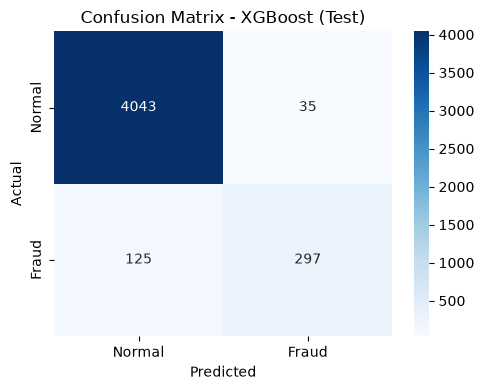

In [23]:

# 3.9.3 - Đánh giá mô hình cuối cùng trên Test

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Dự đoán xác suất trên Test
test_probs = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= final_threshold).astype(int)

# Tính các chỉ số đánh giá
tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

test_results = {
    "Model": final_model_name,
    "Threshold": final_threshold,
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1-score": f1_score(y_test, test_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, test_probs),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}

# Hiển thị bảng đánh giá
display(pd.DataFrame([test_results]).round(4))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title(f"Confusion Matrix - {final_model_name} (Test)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


In [ ]:
# 3.9.4 - Phân tích độ quan trọng của feature

# Lấy tên feature sau khi xử lý
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Lấy độ quan trọng từ đúng mô hình đã chọn
estimator = final_model.named_steps["model"]
if hasattr(estimator, "feature_importances_"):
    importances = estimator.feature_importances_
else:
    importances = np.abs(estimator.coef_[0])

# Tạo bảng kết quả
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sắp xếp từ quan trọng nhất đến ít quan trọng nhất
feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

display(feature_importance.head(10))

# Vẽ 10 feature quan trọng nhất
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 5))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mức độ quan trọng")
plt.title("Top 10 Feature quan trọng nhất")
plt.tight_layout()
plt.show()


In [ ]:
# 3.10.1 - Lưu đúng mô hình cuối cùng và metadata đi kèm

import json
import joblib
from importlib.metadata import version
from pathlib import Path

# Chạy được từ thư mục gốc dự án hoặc notebooks.
PROJECT_DIR = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "notebooks" / "03_Model Training.ipynb").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Hãy chạy notebook trong thư mục dự án")

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "fraud_detection_model.joblib"
METADATA_PATH = MODEL_DIR / "model_metadata.json"

feature_names = list(final_model.feature_names_in_)
if feature_names != list(features):
    raise ValueError("Feature của final_model khác dữ liệu huấn luyện")
if list(final_model.classes_) != [0, 1]:
    raise ValueError("Mô hình phải có hai lớp LEGITIMATE=0 và FRAUD=1")
if not 0 < float(final_threshold) < 1:
    raise ValueError("Threshold phải nằm trong khoảng (0, 1)")

metadata = {
    "model_name": final_model_name,
    "features": feature_names,
    "threshold": float(final_threshold),
    "test_results": {
        key: float(test_results[key])
        for key in ("Precision", "Recall", "F1-score", "PR-AUC")
    },
    "library_versions": {
        package: version(package)
        for package in ("joblib", "scikit-learn", "numpy", "pandas")
    },
}
if final_model_name == "XGBoost":
    import xgboost
    metadata["library_versions"]["xgboost"] = xgboost.__version__

# final_model là mô hình được chọn ở mục 3.9.2, không dùng biến vòng lặp model.
joblib.dump(final_model, MODEL_PATH)
METADATA_PATH.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=4, allow_nan=False) + "\n",
    encoding="utf-8",
)
print("Đã lưu mô hình:", MODEL_PATH)
print("Đã lưu metadata:", METADATA_PATH)


In [ ]:
# 3.10.2 - Load lại chính file vừa lưu và đối soát toàn bộ tập Test

import json
import joblib
import numpy as np
import pandas as pd

loaded_model = joblib.load(MODEL_PATH)
loaded_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
assert list(loaded_model.feature_names_in_) == loaded_metadata["features"] == list(features)
assert list(loaded_model.classes_) == list(final_model.classes_) == [0, 1]
assert loaded_metadata["model_name"] == final_model_name
assert loaded_metadata["threshold"] == float(final_threshold)
assert not X_test.empty, "Không có dữ liệu Test để kiểm tra artifact"

# Kiểm tra mọi mẫu Test; chỉ hiển thị 10 dòng đầu cho gọn.
loaded_probabilities = loaded_model.predict_proba(X_test)
original_probabilities = final_model.predict_proba(X_test)
assert np.isfinite(loaded_probabilities).all(), "Artifact trả xác suất không hợp lệ"
np.testing.assert_allclose(
    loaded_probabilities,
    original_probabilities,
    rtol=1e-10,
    atol=1e-12,
    err_msg="Mô hình tải lại có xác suất khác final_model",
)
fraud_index = list(loaded_model.classes_).index(1)
probabilities = loaded_probabilities[:, fraud_index]
predictions = (probabilities >= loaded_metadata["threshold"]).astype(int)
np.testing.assert_array_equal(
    predictions,
    (original_probabilities[:, fraud_index] >= final_threshold).astype(int),
)

prediction_results = pd.DataFrame({
    "Fraud_Probability": probabilities,
    "Predicted_Label": predictions,
    "Actual_Label": y_test.loc[X_test.index].values,
}, index=X_test.index)
display(prediction_results.head(10).round(4))
print(f"Kiểm tra thành công: {len(X_test):,} mẫu Test khớp final_model sau khi load lại.")
